# Single-Region Comprehensive Validation Pipeline
This notebook executes an end-to-end evaluation for a single calorimeter kinematic region ($E_T \times \eta$):
1. **Split Manifest & Class Balance**: Analyzes signal (photons) vs background (jets) counts in the holdout test partition.
2. **Feature Distributions & Derived Variables**: Computes and visualizes raw features and calculated shower shapes (including $E_{\text{ratio}}$) with class separations.
3. **Training & Metric Curves**: Aggregates fold repeats and renders training loss, SP index, and ROC curves.
4. **Efficiency Validation**: Evaluates detection efficiency and false-alarm response against baseline thresholds.
5. **Quadrant Analysis (Model vs Cut)**: Benchmarks the best model against Athena fast photon linear cuts.
6. **Feature Distributions with Model Selections**: Overlays accepted events (black dots) on signal/background feature histograms for both the ML model and linear cuts.
7. **Model vs Model Comparison**: Executes holdout quadrant comparison against a secondary model configuration.



In [ ]:
%load_ext autoreload
%autoreload 2

import os
import sys
from pathlib import Path

# Resolve repository root
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import torch
import yaml
import matplotlib.pyplot as plt
import mplhep as mh

mh.style.use("ATLAS")

from src.Parser.NeuralRingerTrainerConfiguration import NeuralRingerTrainerConfiguration
from src.core.Trainers.NeuralRingerTrainer import NeuralRingerTrainer
from src.core.Datasets.SplitManifest import SplitManifest
from src.core.Validation.ResultAggregator import ResultAggregator
from src.core.Validation.HoldoutEvaluator import HoldoutEvaluator, HoldoutEvaluationResult
from src.core.Validation.EfficiencyPlotter import EfficiencyPlotter
from src.core.Validation.QuadrantAnalyzer import QuadrantAnalyzer, StrategyMetrics
from src.core.Plotting.FeatureDistributionPlotter import FeatureDistributionPlotter
from scipy import stats
from src.core.Plotting.QuadrantPlotter import QuadrantPlotter
from src.core.Plotting.PlotManager import PlotManager
from src.utils import (
    get_et_eta,
    save_table,
    extract_feature_values,
    compute_js_divergence_with_uncertainty,
)
from src.core.Validation.DistributionComparator import DistributionComparator
from src.core.Validation.PileupAnalyzer import PileupAnalyzer
from src.core.Validation.PileupThresholdCalibrator import (
    PileupThresholdCalibrator,
    OperatingPointCalibration,
)
from src.core.Plotting.PileupPlotter import PileupPlotter
from src.core.Validation.QuadrantAnalyzer import RegionalQuadrantResult


print(f"Project root: {PROJECT_ROOT}")
print(f"PyTorch version: {torch.__version__}, CUDA available: {torch.cuda.is_available()}")


Project root: /eos/home-i04/p/pmourafr/egamma_master
PyTorch version: 2.10.0, CUDA available: True


### Centralized Configuration Constants
All parameters, paths, and region selections are defined below:



In [2]:
# --- Target Kinematic Region ---
TARGET_ET: int = 1
TARGET_ETA: int = 1
REGION_KEY: str = f"et_{TARGET_ET}_eta_{TARGET_ETA}"

# --- Validation & Operating Point Constants ---
TARGET_PD: float = 0.9424
EFFICIENCIES_CSV: Path | None = None
THRESHOLD_MODE: str = "calibrated"  # 'calibrated' for target PD cut, 'default' for 0.5 threshold
WORKING_POINT: str = "loose"        # Athena fast photon cut: 'loose', 'medium', 'tight'
PLOT_FORMAT: str = "png"            # 'png' or 'pdf'
LOG_Y_SECTION_6: bool = False  # Enable logarithmic Y-axis scale for Section 6 feature plots

# --- Model 1 (Primary Model) Paths ---
CONFIG_PATH_1: Path = PROJECT_ROOT / "config/NeuralRinger/ModelV9_HighBatch_100Rings.yaml"
RESULTS_PATH_1: Path = PROJECT_ROOT / "results/config_nameModelV9_HighBatch_100Rings_id20261105222012"
MODEL_1_ALIAS: str = "Model V9 (100 Rings)"

# --- Model 2 (Secondary Comparison Model) ---
ENABLE_MODEL2_COMPARISON: bool = True
CONFIG_PATH_2: Path = PROJECT_ROOT / "config/NeuralRinger/ModelV9_HighBatch_50Rings.yaml"
RESULTS_PATH_2: Path = PROJECT_ROOT / "results/config_nameModelV9_HighBatch_50Rings_id20261109122259"
MODEL_2_ALIAS: str = "Model V9 (50 Rings)"

ATHENA_ALIAS: str = f"Athena {WORKING_POINT.capitalize()} Cut"

# --- Common Data & Output Directories ---
DATA_PATH: Path = PROJECT_ROOT / "data/consolidated"
MANIFEST_PATH: Path = RESULTS_PATH_1.parent / "split_manifest.json"
OUTPUT_DIR: Path = PROJECT_ROOT / "notebooks" / f"SingleRegionValidation_{RESULTS_PATH_1.name}"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
TRUE_DATA_PLOTS_DIR: Path = PROJECT_ROOT / "notebooks/TrueDataPlots"
TRUE_DATA_PLOTS_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR: Path = OUTPUT_DIR / "Tables"
TABLES_DIR.mkdir(parents=True, exist_ok=True)
TRUE_DATA_TABLES_DIR: Path = TRUE_DATA_PLOTS_DIR / "Tables"
TRUE_DATA_TABLES_DIR.mkdir(parents=True, exist_ok=True)

# --- Features to Inspect & Histogram (including derived Eratio) ---
FEATURES_TO_PLOT: list[str] = [
    "trig_L2_calo_et",
    "trig_L2_calo_eta",
    "trig_L2_calo_phi",
    "trig_L2_calo_e237",
    "trig_L2_calo_e277",
    "trig_L2_calo_fracs1",
    "trig_L2_calo_weta2",
    "trig_L2_calo_ehad1",
    "trig_L2_calo_emaxs1",
    "trig_L2_calo_e2tsts1",
    "trig_L2_calo_wstot",
    "Eratio",
]

print(f"Target Region:        {REGION_KEY} (ET={TARGET_ET}, ETA={TARGET_ETA})")
print(f"Primary Config:       {CONFIG_PATH_1}")
print(f"Primary Results:      {RESULTS_PATH_1}")
print(f"Output Directory:     {OUTPUT_DIR}")
print(f"True Data Plots:      {TRUE_DATA_PLOTS_DIR}")
print(f"Tables Directory:     {TABLES_DIR}")
print(f"True Data Tables:     {TRUE_DATA_TABLES_DIR}")
print(f"Target Efficiency:    {TARGET_PD * 100:.2f}%")
print(f"Athena Working Point: {WORKING_POINT.capitalize()}")
print(f"Features configured:  {len(FEATURES_TO_PLOT)} variables")
print(f"Section 6 Log Y Scale:  {LOG_Y_SECTION_6}")
print(f"Model 1 Alias:        {MODEL_1_ALIAS}")
print(f"Model 2 Alias:        {MODEL_2_ALIAS}")
print(f"Athena Alias:         {ATHENA_ALIAS}")


Target Region:        et_1_eta_1 (ET=1, ETA=1)
Primary Config:       /eos/home-i04/p/pmourafr/egamma_master/config/NeuralRinger/ModelV9_HighBatch_100Rings.yaml
Primary Results:      /eos/home-i04/p/pmourafr/egamma_master/results/config_nameModelV9_HighBatch_100Rings_id20261105222012
Output Directory:     /eos/home-i04/p/pmourafr/egamma_master/notebooks/SingleRegionValidation_config_nameModelV9_HighBatch_100Rings_id20261105222012
True Data Plots:      /eos/home-i04/p/pmourafr/egamma_master/notebooks/TrueDataPlots
Tables Directory:     /eos/home-i04/p/pmourafr/egamma_master/notebooks/SingleRegionValidation_config_nameModelV9_HighBatch_100Rings_id20261105222012/Tables
True Data Tables:     /eos/home-i04/p/pmourafr/egamma_master/notebooks/TrueDataPlots/Tables
Target Efficiency:    94.24%
Athena Working Point: Loose
Features configured:  12 variables
Section 6 Log Y Scale:  False
Model 1 Alias:        Model V9 (100 Rings)
Model 2 Alias:        Model V9 (50 Rings)
Athena Alias:         Athen

### 1. Data Loading & Test Set Class Distribution Analysis
Loads dataset samples for the configured region, retrieves the deterministic test partition from [`SplitManifest`](file:///home/pmourafr/egamma_master/src/core/Datasets/SplitManifest.py), and computes class counts:



Loaded dataset file: /eos/home-i04/p/pmourafr/egamma_master/data/consolidated/consolidated.et1.eta1.npz
Total events in region: 143,780


,Partition,Signal (Photons),Background (Jets),Total Events,Signal Fraction,Background Fraction
0,Holdout Test Set,3994,10384,14378,27.78%,72.22%
1,Train / Val Set,35938,93464,129402,27.77%,72.23%
2,Full Region Data,39932,103848,143780,27.77%,72.23%


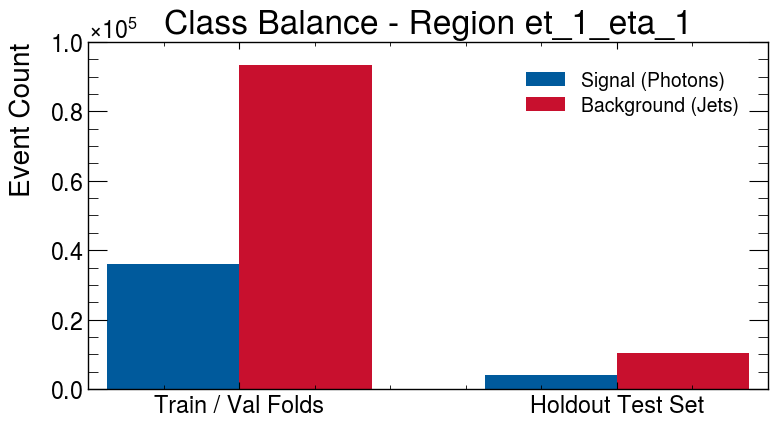

In [3]:
with open(CONFIG_PATH_1, "r") as f:
    config_dict_1 = yaml.safe_load(f)

if DATA_PATH.exists():
    config_dict_1["dataset"]["parameters"]["drive_path"] = str(DATA_PATH)

config_1 = NeuralRingerTrainerConfiguration.model_validate(config_dict_1)
trainer_1 = NeuralRingerTrainer(config_1)
full_dataset = trainer_1.full_dataset
feature_names = full_dataset.feature_names

# Locate dataset index matching TARGET_ET and TARGET_ETA
region_file_idx = None
for idx, path_str in enumerate(full_dataset.file_paths):
    iet, ieta = get_et_eta(path_str)
    if iet == TARGET_ET and ieta == TARGET_ETA:
        region_file_idx = idx
        break

if region_file_idx is None:
    raise FileNotFoundError(f"No dataset file matching et={TARGET_ET}, eta={TARGET_ETA} in {DATA_PATH}")

raw_features, raw_labels, region_file_path = full_dataset[region_file_idx]
print(f"Loaded dataset file: {region_file_path}")
print(f"Total events in region: {len(raw_labels):,}")

# Load test split indices from manifest
manifest = SplitManifest(str(MANIFEST_PATH))
if not manifest.exists():
    raise FileNotFoundError(f"Manifest not found at {MANIFEST_PATH}")

manifest.load()
test_indices, train_folds = manifest.get_region_splits(REGION_KEY)
test_indices = np.array(test_indices, dtype=int)

all_indices = np.arange(len(raw_labels))
train_val_mask = ~np.isin(all_indices, test_indices)
test_mask = np.isin(all_indices, test_indices)

test_features = raw_features[test_indices]
test_labels = raw_labels[test_indices]
train_val_labels = raw_labels[train_val_mask]

# Compute class counts
test_sig = int(np.sum(test_labels == 1))
test_bg = int(np.sum(test_labels == 0))
total_test = len(test_labels)

train_sig = int(np.sum(train_val_labels == 1))
train_bg = int(np.sum(train_val_labels == 0))
total_train = len(train_val_labels)

summary_df = pd.DataFrame([
    {
        "Partition": "Holdout Test Set",
        "Signal (Photons)": test_sig,
        "Background (Jets)": test_bg,
        "Total Events": total_test,
        "Signal Fraction": f"{test_sig / total_test:.2%}",
        "Background Fraction": f"{test_bg / total_test:.2%}",
    },
    {
        "Partition": "Train / Val Set",
        "Signal (Photons)": train_sig,
        "Background (Jets)": train_bg,
        "Total Events": total_train,
        "Signal Fraction": f"{train_sig / total_train:.2%}",
        "Background Fraction": f"{train_bg / total_train:.2%}",
    },
    {
        "Partition": "Full Region Data",
        "Signal (Photons)": test_sig + train_sig,
        "Background (Jets)": test_bg + train_bg,
        "Total Events": total_test + total_train,
        "Signal Fraction": f"{(test_sig + train_sig) / (total_test + total_train):.2%}",
        "Background Fraction": f"{(test_bg + train_bg) / (total_test + total_train):.2%}",
    }
])

display(summary_df)
save_table(summary_df, TRUE_DATA_TABLES_DIR, REGION_KEY, "class_distribution_summary")

# Plot class breakdown bar chart
fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(2)
width = 0.35
ax.bar(x - width/2, [train_sig, test_sig], width, label="Signal (Photons)", color="#005A9C")
ax.bar(x + width/2, [train_bg, test_bg], width, label="Background (Jets)", color="#C8102E")
ax.set_xticks(x)
ax.set_xticklabels(["Train / Val Folds", "Holdout Test Set"])
ax.set_ylabel("Event Count")
ax.set_title(f"Class Balance - Region {REGION_KEY}")
ax.legend()
plt.tight_layout()
plt.show()


In [4]:
# Validate configured features
valid_features_to_plot = []
for f in FEATURES_TO_PLOT:
    try:
        _ = extract_feature_values(test_features[:5], feature_names, f)
        valid_features_to_plot.append(f)
    except KeyError as e:
        print(f"Skipping {f}: {e}")

feature_plots_dir = TRUE_DATA_PLOTS_DIR
feature_plots_dir.mkdir(parents=True, exist_ok=True)

n_features = len(valid_features_to_plot)
cols = 2
rows = (n_features + cols - 1) // cols

### 2. Feature Extraction & Distributions by Class Label
Defines the feature extractor (supporting raw columns and calculated variables like $E_{\text{ratio}} = (E_{\text{max1}} - E_{\text{max2}}) / (E_{\text{max1}} + E_{\text{max2}})$) and plots signal vs background histograms:



In [ ]:
fig, axes = plt.subplots(rows, cols, figsize=(14, 4.2 * rows))
axes = np.array(axes).reshape(-1)

for idx, feat_name in enumerate(valid_features_to_plot):
    ax = axes[idx]
    values = extract_feature_values(test_features, feature_names, feat_name)

    val_sig = values[test_labels == 1]
    val_bg = values[test_labels == 0]

    val_sig = val_sig[np.isfinite(val_sig)]
    val_bg = val_bg[np.isfinite(val_bg)]

    all_vals = np.concatenate([val_sig, val_bg])
    low, high = np.percentile(all_vals, 0.5), np.percentile(all_vals, 99.5)
    bins = np.linspace(low, high, 40)

    ax.hist(val_sig, bins=bins, density=False, alpha=0.5, color="#005A9C", label=f"Signal (N={len(val_sig):,})")
    ax.hist(val_bg, bins=bins, density=False, alpha=0.5, color="#C8102E", label=f"Background (N={len(val_bg):,})")

    display_title = r"L2 $E_{\text{ratio}}$" if feat_name.lower() in ["eratio", "eration"] else feat_name
    ax.set_title(f"{display_title} ({REGION_KEY})", pad=14)
    ax.set_xlabel(display_title, loc="center")
    ax.set_yscale('log')
    ax.legend(frameon=True)

    fig_single, ax_single = plt.subplots(figsize=(7, 4.8))
    ax_single.hist(val_sig, bins=bins, density=False, alpha=0.5, color="#005A9C", label=f"Signal (N={len(val_sig):,})")
    ax_single.hist(val_bg, bins=bins, density=False, alpha=0.5, color="#C8102E", label=f"Background (N={len(val_bg):,})")
    ax_single.set_title(f"{display_title} ({REGION_KEY})", pad=14)
    ax_single.set_xlabel(display_title, loc="center")
    ax_single.legend(frameon=True)
    fig_single.tight_layout()
    fig_single.savefig(
        feature_plots_dir / f"{feat_name}_distribution.{PLOT_FORMAT}",
        format=PLOT_FORMAT,
        transparent=False,
        bbox_inches="tight",
    )
    plt.close(fig_single)

# Remove unused subplots if odd number
for j in range(idx + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()
